In [1]:
import pandas as pd
fish = pd.read_csv('https://bit.ly/fish_csv_data')

In [2]:
fish_input = fish[["Weight", "Length", "Diagonal", "Height", "Width"]]
fish_target = fish['Species']

In [3]:
from sklearn.model_selection import train_test_split

train_input, test_input, train_target, test_target = train_test_split(fish_input, fish_target, random_state=42)

In [16]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(train_input)
train_scaled = ss.transform(train_input)
test_scaled = ss.transform(test_input)

In [17]:
from sklearn.linear_model import SGDClassifier

In [18]:
sc = SGDClassifier(loss='log_loss', max_iter=10, random_state=42)
sc.fit(train_scaled, train_target)
print(sc.score(train_scaled, train_target))
print(sc.score(test_scaled, test_target))

0.8319327731092437
0.775


/opt/anaconda3/envs/pytorch_env/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:726: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


In [19]:
sc.partial_fit(train_scaled, train_target)
print(sc.score(train_scaled, train_target))
print(sc.score(test_scaled, test_target))

0.8151260504201681
0.8


In [57]:
import numpy as np
sc = SGDClassifier(loss='perceptron', random_state=42)
train_score = []
test_score = []
classes = np.unique(train_target)

In [58]:
for i in range(1,200):
    sc.partial_fit(train_scaled, train_target, classes=classes)
    train_score.append(sc.score(train_scaled, train_target))
    test_score.append(sc.score(test_scaled, test_target))

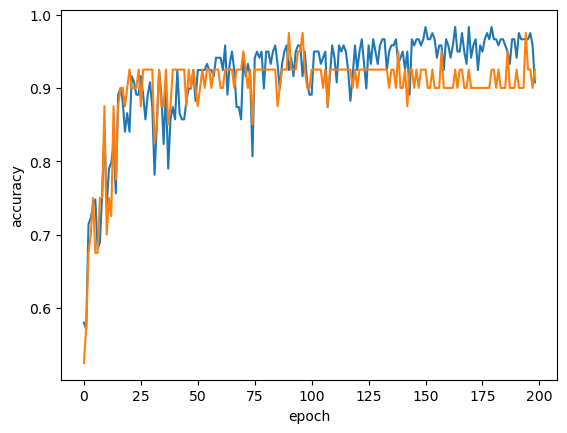

In [59]:
import matplotlib.pyplot as plt 
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

In [60]:
sc = SGDClassifier(loss='perceptron', max_iter=100, tol=None,random_state=42)
sc.fit(train_scaled, train_target)
print(sc.score(train_scaled, train_target))
print(sc.score(test_scaled, test_target))

0.8235294117647058
0.825


In [ ]:
sc = SGDClassifier(loss='hinge', max_iter=100, tol=None,random_state=42)
sc.fit(train_scaled, train_target)
print(sc.score(train_scaled, train_target))
print(sc.score(test_scaled, test_target))

InvalidParameterError: The 'loss' parameter of SGDClassifier must be a str among {'log_loss', 'huber', 'perceptron', 'squared_epsilon_insensitive', 'hinge', 'epsilon_insensitive', 'modified_huber', 'squared_error', 'squared_hinge'}. Got '' instead.

In [ ]:
{'log_loss', 'huber', 'perceptron', 'squared_epsilon_insensitive', 'hinge', 'epsilon_insensitive', 'modified_huber', 'squared_error', 'squared_hinge'}